# El gradiente de Wirtinger y el paso de Adam: un gradiente a través de cualquier modelo directo

**Pregunta:** ¿Cómo llega un gradiente tomado a través del modelo directo a la fase de cada píxel, qué le hace Adam, y qué cambia en el resultado la elección del modelo directo?

- Nivel: 2, el método en la práctica.
- Requisitos previos: `05-optimization/01-the-cost-and-its-gradient`, que presenta el costo y verifica su gradiente.
- Tiempo de lectura: unos 25 minutos. El notebook se ejecuta en cerca de un minuto y medio.

## Objetivos

M11 es el optimizador que usa la holografía de aprendizaje automático: derivar una pérdida a través del modelo que convierte fase en luz y dejar que Adam mueva la fase. Su atractivo es la generalidad, porque el mismo código sirve para cualquier modelo directo que tenga adjunto. Su riesgo es un tamaño de paso fácil de fijar mal. Este notebook abre ambas cosas. Al terminar puedes:

- enunciar el retroceso de Wirtinger y decir por qué un holograma de solo fase necesita un único gradiente real por píxel;
- verificar que el gradiente sobrevive a un cambio de modelo directo, aquí un dispositivo con diafonía entre píxeles, y decir dónde deja de ser válida una verificación por diferencias finitas;
- explicar qué le hace Adam a un gradiente cuya escala no puedes predecir, con el primer paso como evidencia;
- elegir una tasa de aprendizaje a partir de un barrido y no de un artículo;
- mostrar qué le hace al holograma mostrado en un dispositivo la elección del modelo directo.

## Preparación


El entorno de notebooks está fijado en `notebooks/requirements.txt` y se construye con `scripts/setup.sh --notebooks`
(`scripts/setup.ps1 -Notebooks` en Windows). Este notebook usa dos paquetes, con estas versiones exactas:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

DinHot no publica un paquete propio: sus métodos viven en la carpeta del pipeline `data-pipeline/`, y la celda siguiente
pone esa carpeta en la ruta de importación e importa las funciones que el notebook llama.

In [1]:
# las herramientas, sus versiones y la carpeta del pipeline en la ruta de importación
import sys
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases import build
from pipeline.core import score as scoring
from pipeline.io.contract import read_cases
from pipeline.model.holo.core.device import Device
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.types import Budget
from pipeline.model.holo.methods.baseline import m04_gs, m06_gsw
from pipeline.model.holo.methods.optim import m11_wirtinger_adam
from pipeline.model.holo.methods.optim.costs import TrapCost

print("numpy", version("numpy"), "| matplotlib", version("matplotlib"))

numpy 2.4.6 | matplotlib 3.11.2


## Datos

El notebook lee el caso C12 de `data/examples/cases.json`, la misma tarea de calibración de 10 x 10 del notebook anterior.

- Propietario: este repositorio; el caso es sintético y sigue la tarea de Di Leonardo, Ianni y Ruocco (2007).
- Clase de licencia: datos generados bajo la licencia del propio repositorio, sin conjuntos de datos de terceros.
- Archivo: `data/examples/cases.json`, caso C12.

In [2]:
# caso C12: el montaje óptico y las 100 trampas de la tarea de 10 x 10
rec = {c["case_id"][:3]: c for c in read_cases(ROOT / "data/examples/cases.json")}["C12"]
setup = build.setup_of(rec)
target = build.target_of(rec)
n = setup.n_pix
print(rec["case_id"], "|", len(target.traps), "trampas | SLM", n, "x", n, "píxeles")

C12_calibration | 100 trampas | SLM 256 x 256 píxeles


## Método

### Paso 1: el retroceso, y un modelo directo que no es el ideal

Para una pérdida real $L(I)$ de las intensidades $I = |z|^2$, con $z$ el campo complejo en las trampas, la derivada respecto de las partes real e imaginaria de $z$ se combina en un solo número complejo, el gradiente de Wirtinger $G = \partial L / \partial z^* = L'(I)\,z$. Si $z = \mathrm{Op}(f)$ es una función lineal del campo en el SLM $f_j = A_j e^{i\phi_j}$, la regla de la cadena da la derivada respecto de cada fase, $\partial L / \partial \phi_j = 2\,\mathrm{Re}\,(i f_j\,\overline{(\mathrm{Op}^H G)_j})$ (Chakravarthula et al., 2019, ecs. 5 a 8). Como el SLM es de solo fase, $f_j$ lleva un parámetro real, y el gradiente completo es un número real por píxel, calculado con una aplicación directa y una adjunta del modelo.

Nada en esa derivación dice que el modelo sea una transformada de Fourier simple. El pipeline ofrece el mismo retroceso para un dispositivo cuyos píxeles se filtran hacia sus vecinos: la fase se sobremuestrea 3 x 3, se difumina con el núcleo de diafonía de Schroff et al. (2023), se transforma y se lee en las trampas. La celda compara el gradiente analítico con diferencias centrales a través del modelo ideal y de ese dispositivo (sigma 1,24 por píxel, exponente 1,8, factor de llenado 0,85), con cuatro tamaños de paso. La última columna cuenta cuántos de los 65536 píxeles empuja la perturbación a través del salto en 0 y $2\pi$, lo que importa para el modelo con diafonía.

In [3]:
# la verificación del gradiente anterior a través de dos modelos directos: FFT ideal y un dispositivo con
# diafonía
device = Device(crosstalk=(1.24, 1.8), upsample=3, fill_factor=0.85)
rng = Rng(8)
phi0 = rng.phases(n**2).reshape(n, n)
direction = rng.normal_array(n**2).reshape(n, n)
direction /= np.linalg.norm(direction)
errors = {}
for name, dev in (("ideal", None), ("crosstalk", device)):
    cost = TrapCost(setup, target.traps, dev, t=2, efficiency=0.9)
    slope = float(np.sum(cost.value_grad(phi0)[1] * direction))
    for h in (1e-1, 1e-2, 1e-3, 1e-4):
        up, down = cost.value_grad(phi0 + h * direction)[0], cost.value_grad(phi0 - h * direction)[0]
        errors[name, h] = abs((up - down) / (2 * h) - slope) / abs(slope)
for h in (1e-1, 1e-2, 1e-3, 1e-4):
    wrapped = int(np.sum((phi0 + h * direction >= 2 * np.pi) | (phi0 + h * direction < 0)))
    print(f"h {h:.0e}: ideal {errors['ideal', h]:.1e} | diafonía {errors['crosstalk', h]:.1e}")
    print(f"        píxeles empujados a través del salto de 2 pi: {wrapped}")

h 1e-01: ideal 1.2e-07 | diafonía 4.5e+02
        píxeles empujados a través del salto de 2 pi: 2
h 1e-02: ideal 3.5e-10 | diafonía 3.0e+03
        píxeles empujados a través del salto de 2 pi: 1
h 1e-03: ideal 4.0e-09 | diafonía 2.3e-07
        píxeles empujados a través del salto de 2 pi: 0
h 1e-04: ideal 6.9e-08 | diafonía 7.4e-06
        píxeles empujados a través del salto de 2 pi: 0


A través del modelo ideal el gradiente analítico es correcto en cada paso, con un error relativo entre 3,5e-10 y 1,2e-7. A través del dispositivo con diafonía es correcto a 2,3e-07 con h = 0,001 y a 7,4e-06 con h = 0,0001, de modo que el mismo retroceso vale para un modelo directo que incluye un sobremuestreo, una convolución con un núcleo y una apertura de píxel. Con h = 0,1 y h = 0,01 la verificación con diafonía falla por tres órdenes de magnitud o más, y la última columna dice por qué: uno o dos píxeles fueron empujados a través del salto. El modelo mantiene la fase dentro de una vuelta antes de difuminarla, de modo que un píxel empujado a través del salto cambia la fase difuminada en $2\pi$ en su vecindad, y una diferencia finita que lo cruza mide un salto y no una pendiente. El gradiente no está mal ahí; la verificación está fuera de su validez. Una verificación de este tipo debe usar un paso lo bastante pequeño para que ningún píxel cruce un salto. Lo que no prueba es el cuantizador de un dispositivo real, cuyo redondeo tiene pendiente cero casi en todas partes; el pipeline lo trata como identidad en el paso hacia atrás (un estimador de paso directo), y una diferencia finita no coincidiría con eso por diseño.

### Paso 2: qué le hace Adam a un gradiente de escala desconocida

El gradiente del costo normalizado es diminuto y no tiene una unidad natural: su mediana por píxel es del orden de $10^{-6}$ y cambiaría en órdenes de magnitud con el número de trampas o con la eficiencia objetivo. Adam (Kingma y Ba, 2015) está hecho para ser indiferente a esa escala. Mantiene promedios móviles del gradiente y de su cuadrado, $m_k = \beta_1 m_{k-1} + (1 - \beta_1) g_k$ y $v_k = \beta_2 v_{k-1} + (1 - \beta_2) g_k^2$, corrige su sesgo de arranque a $\hat m_k$ y $\hat v_k$, y mueve cada píxel en $\mathrm{lr}\,\hat m_k / (\sqrt{\hat v_k} + \epsilon)$ con $\beta_1 = 0{,}9$, $\beta_2 = 0{,}999$ y $\epsilon = 10^{-8}$ en el pipeline. En el primer paso $\hat m = g$ y $\hat v = g^2$, así que el movimiento es $\mathrm{lr}\,g / (|g| + \epsilon)$: un píxel cuyo gradiente es mucho mayor que $\epsilon$ se mueve casi exactamente la tasa de aprendizaje, sea cual sea el tamaño del gradiente.

La celda parte con las tasas 0,1 y 1,0 desde el mismo patrón de fase aleatorio, ejecuta M11 una iteración y mide cuánto se movió cada píxel.

In [4]:
# el primer paso de Adam de cada píxel frente al tamaño de su gradiente (costo del modelo ideal)
cost = TrapCost(setup, target.traps, None, t=2, efficiency=0.9)
grad0 = np.abs(cost.value_grad(phi0)[1]).ravel()
first = {lr: m11_wirtinger_adam.run(setup, target, budget=Budget(1), rng=Rng(1), init=phi0, lr=lr) for lr in (0.1, 1.0)}
moved = {lr: np.abs(np.angle(np.exp(1j * (res.phi - phi0)))).ravel() for lr, res in first.items()}
print(f"gradiente mediano por píxel: {np.median(grad0):.2e}")
for lr, size in moved.items():
    print(f"lr {lr}: paso mediano {np.median(size):.4f} rad | "
          f"paso mayor {size.max():.4f} rad")

gradiente mediano por píxel: 9.93e-07
lr 0.1: paso mediano 0.0990 rad | paso mayor 0.0999 rad
lr 1.0: paso mediano 0.9900 rad | paso mayor 0.9991 rad


El gráfico de dispersión muestra el movimiento de 3000 píxeles frente a su gradiente, junto con la forma cerrada.

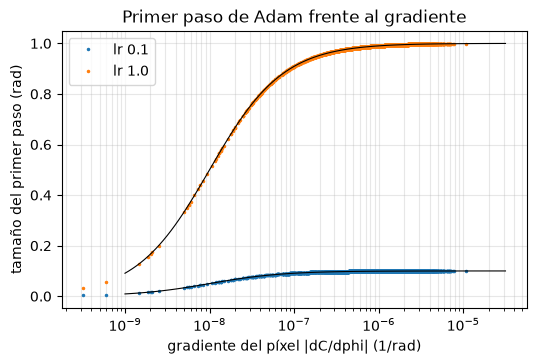

In [5]:
# tamaño del paso frente al tamaño del gradiente en 3000 píxeles, con la forma cerrada lr g / (g + eps)
pick = np.random.default_rng(3).choice(grad0.size, 3000, replace=False)
g_axis = np.logspace(-9, -4.5, 100)
fig, ax = plt.subplots(figsize=(6.0, 3.6))
for lr, size in moved.items():
    ax.semilogx(grad0[pick], size[pick], ".", markersize=3, label=f"lr {lr}")
    ax.semilogx(g_axis, lr * g_axis / (g_axis + 1e-8), "k-", linewidth=0.8)
ax.set_xlabel("gradiente del píxel |dC/dphi| (1/rad)")
ax.set_ylabel("tamaño del primer paso (rad)")
ax.set_title("Primer paso de Adam frente al gradiente")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.show()

Los puntos caen sobre las curvas negras. Para gradientes sobre unos $10^{-7}$ el paso se satura en la tasa de aprendizaje, 0,1 o 1,0 rad; solo los píxeles con los gradientes más pequeños, a la izquierda del codo en $\epsilon = 10^{-8}$, se mueven menos. Con el gradiente mediano en 9,93e-07 el píxel típico se mueve 0,99 de la tasa de aprendizaje, de modo que con lr = 1 la primera iteración gira casi todos los píxeles cerca de un radián completo, un movimiento grande y grueso del que el holograma tiene que recuperarse. Eso es lo que hace de la tasa de aprendizaje el único parámetro que importa: Adam sacó la escala del gradiente del problema y dejó el paso en radianes. El gráfico no muestra cómo se comportan los pasos después del primero, cuando los promedios móviles guardan memoria y el movimiento se reduce a medida que los gradientes coinciden menos de una iteración a otra; el barrido siguiente mide ese efecto sobre el resultado.

### Paso 3: elegir la tasa de aprendizaje

El artículo de Chakravarthula et al. usa Adam con una tasa de aprendizaje de 0,001 para pérdidas aprendidas. El pipeline guarda ese valor como `PAPER_LR` y usa uno ajustado, 1,0, para esta pérdida. La celda pone a prueba esa elección en lugar de repetirla: cuatro tasas de aprendizaje, 30 iteraciones cada una, el mismo inicio.

In [6]:
# 30 iteraciones de Wirtinger-Adam con cuatro tasas de aprendizaje; 0.001 es el valor del artículo
rates = (0.001, 0.1, 1.0, 4.0)
sweep = {lr: m11_wirtinger_adam.run(setup, target, budget=Budget(30), rng=Rng(1), lr=lr).history for lr in rates}
for lr, hist in sweep.items():
    last = hist[-1]
    print(f"lr {lr:>5}: eficiencia {last['efficiency']:.4f}  "
          f"desv. rel. {last['rel_std']:7.2f} %  pérdida {last['loss']:.4f}")

lr 0.001: eficiencia 0.0033  desv. rel.   91.94 %  pérdida 0.9927
lr   0.1: eficiencia 0.6863  desv. rel.   11.48 %  pérdida 0.0640
lr   1.0: eficiencia 0.7629  desv. rel.    2.56 %  pérdida 0.0237
lr   4.0: eficiencia 0.4600  desv. rel.   14.02 %  pérdida 0.2441


Las curvas de las mismas cuatro corridas muestran cómo llega cada una a su valor final, o no llega.

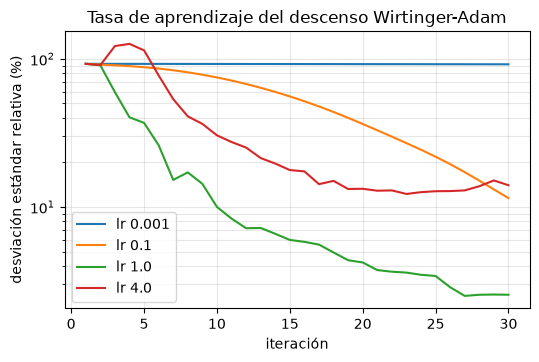

In [7]:
# desviación estándar relativa de las trampas frente a la iteración, una curva por tasa de aprendizaje
fig, ax = plt.subplots(figsize=(6.0, 3.6))
for lr, hist in sweep.items():
    ax.semilogy([h["iteration"] for h in hist], [h["rel_std"] for h in hist], label=f"lr {lr}")
ax.set_xlabel("iteración")
ax.set_ylabel("desviación estándar relativa (%)")
ax.set_title("Tasa de aprendizaje del descenso Wirtinger-Adam")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.show()

El barrido tiene un óptimo claro, y no es el valor del artículo. Con 0,001 las 30 iteraciones mueven cada píxel como máximo 0,03 rad en total, de modo que el holograma sigue siendo el inicio aleatorio: eficiencia 0,003 y una dispersión de 91,94 por ciento. Con 0,1 el descenso funciona pero es lento, y termina en 11,48 por ciento. Con 1,0 llega a 2,56 por ciento. Con 4,0 los pasos son mayores que la estructura del patrón de fase, la pérdida sube y la corrida termina en 14,02 por ciento con una eficiencia de 0,46, peor que la corrida con 0,1. Las curvas muestran que la tasa de aprendizaje cambia velocidad por sobrepaso en una banda angosta. No muestran que 1,0 sea la mejor para toda tarea: el registro de ajuste del pipeline la eligió en esta tarea de 10 x 10 con semillas separadas, y una tarea con 1000 trampas se ajustaría de nuevo. La regla práctica es barrer la tasa en una corrida corta antes de gastar una larga.

### Paso 4: el modelo directo decide para qué sirve el holograma

La verificación anterior mostró que el gradiente es correcto a través del dispositivo con diafonía. La pregunta es si usarlo importa. La celda optimiza M11 durante 15 iteraciones sobre el modelo ideal, que no ve la diafonía, y muestra el holograma en el dispositivo de la verificación, evaluándolo con el evaluador único del pipeline.

In [8]:
# M11 optimizado sobre el modelo ideal, 15 iteraciones, y luego mostrado en el dispositivo con diafonía de
# la verificación anterior
res_ideal = m11_wirtinger_adam.run(setup, target, budget=Budget(15), rng=Rng(1))
on_device = {"modelo ideal": scoring.score(rec, res_ideal.phi, setup=setup, device=device)}
print(f"modelo ideal, en la pantalla ideal: desv. rel. {res_ideal.history[-1]['rel_std']:.2f} %")
print(f"el mismo holograma en el dispositivo: "
      f"desv. rel. {list(on_device.values())[0]['rel_std_pct']:.2f} %")

modelo ideal, en la pantalla ideal: desv. rel. 5.99 %
el mismo holograma en el dispositivo: desv. rel. 14.27 %


Al mismo optimizador se le da ahora el dispositivo en su modelo directo, con el mismo inicio, la misma tasa de aprendizaje y el mismo número de iteraciones. Nada más cambia: el retroceso del Paso 1 lleva el gradiente a través del sobremuestreo y del núcleo.

In [9]:
# M11 con el dispositivo en su modelo directo, las mismas 15 iteraciones, evaluado en el mismo dispositivo
res_aware = m11_wirtinger_adam.run(setup, target, device=device, budget=Budget(15), rng=Rng(1))
on_device["modelo del dispositivo"] = scoring.score(rec, res_aware.phi, setup=setup, device=device)
for name, s in on_device.items():
    print(f"{name:18s} eficiencia {s['efficiency']:.4f}  desv. rel. {s['rel_std_pct']:.2f} %")

modelo ideal       eficiencia 0.5956  desv. rel. 14.27 %
modelo del dispositivo eficiencia 0.5724  desv. rel. 8.68 %


El holograma optimizado para la pantalla ideal tiene una desviación estándar relativa de 5,99 por ciento tras 15 iteraciones, y en el dispositivo con diafonía muestra 14,27 por ciento con una eficiencia de 0,5956: el dispositivo más que duplica la dispersión. El mismo optimizador con el dispositivo en su modelo directo llega a 8,68 por ciento en ese dispositivo, con una eficiencia de 0,5724, de modo que elimina cerca de dos tercios de la dispersión que añadió el dispositivo y paga 0,0232 de la luz por ello. Nada del optimizador cambió, solo el modelo a través del cual se retrocede el gradiente, y ese es el sentido del método: el costo de la generalidad es cómputo, aquí una pasada directa y una adjunta del modelo sobremuestreado por iteración, y su ganancia es que el holograma se juzga donde se muestra. La comparación es de 15 iteraciones, una semilla y un dispositivo; no dice cuánto recupera una corrida más larga, y no incluye el cuantizador, cuyo gradiente de paso directo la verificación anterior no pudo probar.

## Resultados

**Respuesta:** Un gradiente a través del modelo directo llega a la fase de cada píxel porque el retroceso de Wirtinger entrega una derivada exacta por píxel para cualquier modelo lineal, y Adam convierte esa derivada en un paso cuyo tamaño es solo la tasa de aprendizaje. La derivada es exacta: coincide con las diferencias centrales en 3,5e-10 a través del modelo ideal con h = 0,01 y en 2,3e-07 a través de un dispositivo con diafonía con h = 0,001. La tasa de aprendizaje decide hasta dónde llega el descenso: a las 30 iteraciones la desviación estándar relativa de las trampas es 91,94 por ciento con el 0,001 del artículo, 11,48 con 0,1, 2,56 con 1,0 y 14,02 con 4,0. El modelo directo decide para qué sirve el holograma: optimizado en la pantalla ideal, un holograma tiene 5,99 por ciento de dispersión y muestra 14,27 por ciento en el dispositivo con diafonía, y las mismas 15 iteraciones con el dispositivo en el modelo directo dan 8,68 por ciento ahí.

Lo que el notebook no probó es el cuantizador de paso directo, una corrida más larga en el dispositivo, ni un objetivo distinto de la tarea de 10 x 10.

## Resumen

- El retroceso de Wirtinger da el gradiente de fase de cualquier pérdida a través de cualquier modelo directo lineal, un número real por píxel.
- El gradiente sigue siendo exacto a través de un dispositivo con diafonía; una verificación por diferencias finitas de ese modelo debe mantener el paso bajo el tamaño que empuja píxeles a través del salto de fase.
- Adam elimina la escala del gradiente, de modo que su primer paso es la tasa de aprendizaje misma para casi todos los píxeles.
- La tasa de aprendizaje tiene un óptimo angosto en esta tarea, 1,0, y el 0,001 del artículo no mueve el holograma en 30 iteraciones.
- Darle al optimizador el dispositivo en su modelo directo es todo el método que conoce el dispositivo; el holograma que devuelve se juzga en el dispositivo, no en la pantalla ideal.

## Referencias

- Chakravarthula et al. (2019). Wirtinger holography for near-eye displays. ACM Transactions on Graphics 38, 213. https://doi.org/10.1145/3355089.3356539
- Schroff et al. (2023). Accurate holographic light potentials using pixel crosstalk modelling. Scientific Reports 13, 3252. https://doi.org/10.1038/s41598-023-30296-6
- Di Leonardo, Ianni and Ruocco (2007). Computer generation of optimal holograms for optical trap arrays. Optics Express 15, 1913. https://doi.org/10.1364/OE.15.001913
- Kingma and Ba (2015). Adam: a method for stochastic optimization. https://arxiv.org/abs/1412.6980